In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar la carpeta principal del proyecto
RUTA_PROYECTO = Path.cwd().parent

# Cargar los datos
ruta_csv = RUTA_PROYECTO / "data" / "online_shoppers_intention.csv"
datos = pd.read_csv(ruta_csv)

# Mostrar las dimensiones
print("Dimensiones:", datos.shape)

# Mostrar las primeras filas
display(datos.head())

Dimensiones: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar la carpeta principal del proyecto
RUTA_PROYECTO = Path.cwd().parent

# Cargar los datos
ruta_csv = RUTA_PROYECTO / "data" / "online_shoppers_intention.csv"
datos = pd.read_csv(ruta_csv)

# Mostrar las dimensiones
print("Dimensiones:", datos.shape)

# Mostrar las primeras filas
display(datos.head())

Dimensiones: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Cantidad de sesiones sin compra: 10422
Cantidad de sesiones con compra: 1908

Porcentajes:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


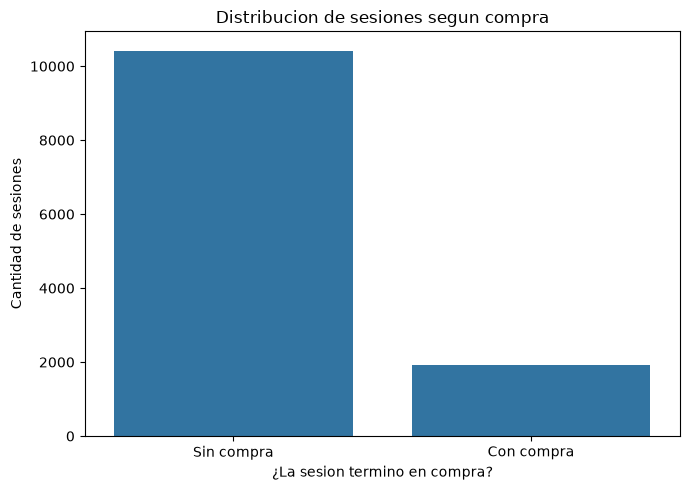

In [2]:

# Distribucion de sesiones con compra y sin compra

distribucion = datos["Revenue"].value_counts().sort_index()

print("Cantidad de sesiones sin compra:", distribucion[False])
print("Cantidad de sesiones con compra:", distribucion[True])

print("\nPorcentajes:")
print((datos["Revenue"].value_counts(normalize=True) * 100).round(2))

# Crear grafico
plt.figure(figsize=(7, 5))

sns.countplot(data=datos, x="Revenue")

plt.title("Distribucion de sesiones segun compra")
plt.xlabel("¿La sesion termino en compra?")
plt.ylabel("Cantidad de sesiones")

plt.xticks(
    ticks=[0, 1],
    labels=["Sin compra", "Con compra"]
)

plt.tight_layout()
plt.show()


Revenue  False  True 
Month                
Aug        357     76
Dec       1511    216
Feb        181      3
Jul        366     66
June       259     29
Mar       1715    192
May       2999    365
Nov       2238    760
Oct        434    115
Sep        362     86


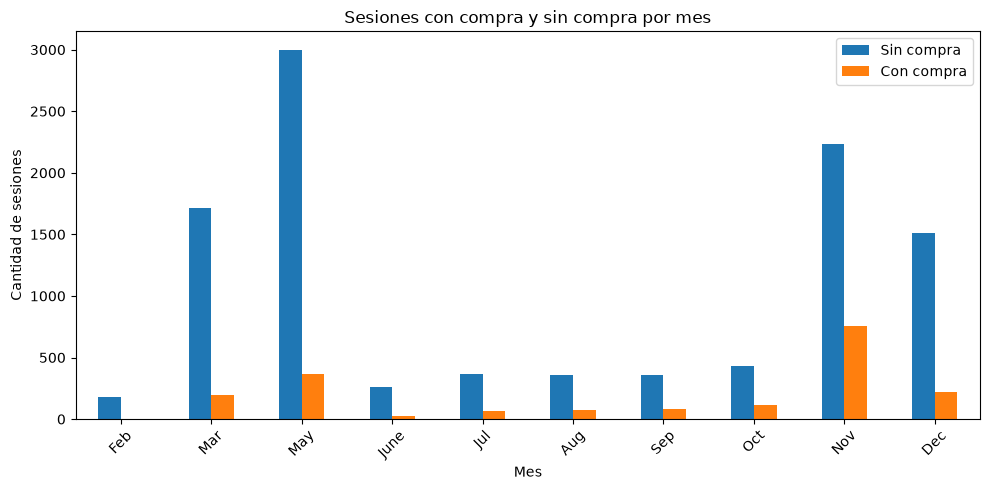

In [3]:

# Cantidad de sesiones por mes y resultado de compra

tabla_meses = pd.crosstab(
    datos["Month"],
    datos["Revenue"]
)

print(tabla_meses)

# Orden cronologico de los meses presentes en el dataset
orden_meses = [
    "Feb", "Mar", "May", "June",
    "Jul", "Aug", "Sep", "Oct",
    "Nov", "Dec"
]

meses_presentes = [
    mes for mes in orden_meses
    if mes in datos["Month"].unique()
]

tabla_meses = tabla_meses.reindex(meses_presentes)

# Grafico
tabla_meses.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sesiones con compra y sin compra por mes")
plt.xlabel("Mes")
plt.ylabel("Cantidad de sesiones")
plt.xticks(rotation=45)
plt.legend(["Sin compra", "Con compra"])
plt.tight_layout()
plt.show()


PROMEDIO DE LAS VARIABLES SEGUN REVENUE


,PageValues,BounceRates,ExitRates
Revenue,,,
False,1.975998,0.025317,0.047378
True,27.264518,0.005117,0.019555


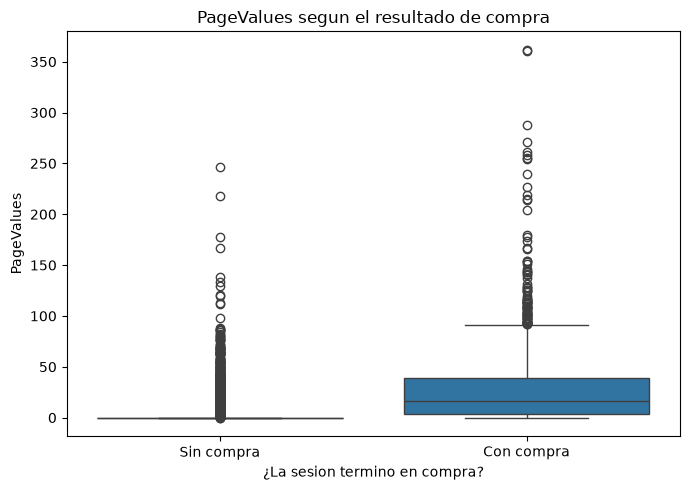

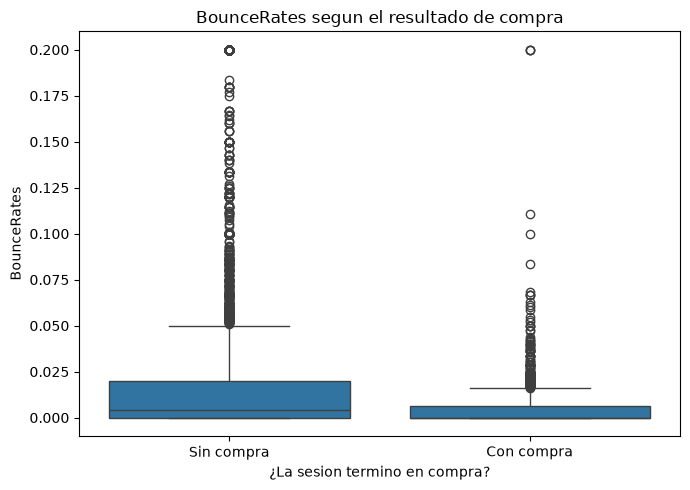

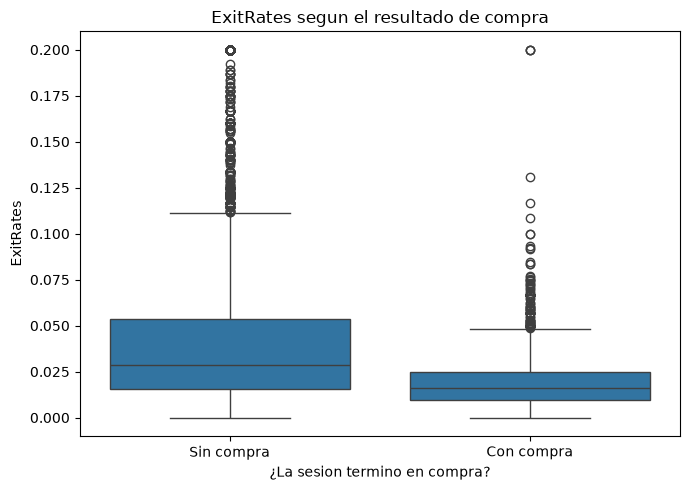

In [4]:

# Comparar variables segun el resultado de la sesion

variables = ["PageValues", "BounceRates", "ExitRates"]

print("PROMEDIO DE LAS VARIABLES SEGUN REVENUE")
display(datos.groupby("Revenue")[variables].mean())

# Crear un grafico por cada variable
for variable in variables:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=datos,
        x="Revenue",
        y=variable
    )

    plt.title(f"{variable} segun el resultado de compra")
    plt.xlabel("¿La sesion termino en compra?")
    plt.ylabel(variable)

    plt.xticks(
        ticks=[0, 1],
        labels=["Sin compra", "Con compra"]
    )

    plt.tight_layout()
    plt.show()


In [5]:

import numpy as np

# Comprobar valores infinitos en columnas numericas
columnas_numericas = datos.select_dtypes(include="number").columns

infinitos = np.isinf(datos[columnas_numericas]).sum()

print("VALORES INFINITOS POR COLUMNA")
print(infinitos[infinitos > 0])

# Revisar tipos de datos
print("\nTIPOS DE DATOS")
print(datos.dtypes)

# Revisar categorias de las columnas de texto
print("\nCATEGORIAS DE MONTH")
print(sorted(datos["Month"].dropna().unique()))

print("\nCATEGORIAS DE VISITORTYPE")
print(datos["VisitorType"].value_counts(dropna=False))


VALORES INFINITOS POR COLUMNA
Series([], dtype: int64)

TIPOS DE DATOS
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

CATEGORIAS DE MONTH
['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']

CATEGORIAS DE VISITORTYPE
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64
